# RQ1 check: does the cone change the best option more than random removal?

RQ1 found that restricting the options to teammates inside the 120 degree cone changes the best option in 57.9 percent of passes. Part of that is expected whatever the cone does: the cone keeps only about a third of the teammates, and removing teammates from a list often removes the best one.

This notebook tests whether the **direction** of the cone matters, as suggested in supervisor feedback. For every pass, the same number of teammates as the cone keeps is kept **at random** instead, and the best option is recomputed. If the real cone changes the best option more often than random removal, the direction of the cone carries information beyond the number of teammates it removes.

**A worked example.** A pass has 8 teammates in the freeze frame and 3 are inside the cone. Keeping 3 teammates at random keeps the best one with probability 3/8, so it changes the best option with probability 5/8 = 62.5 percent. The cone is compared with that number, pass by pass.

**Definition used.** The best option changes when the best value among the kept teammates is lower than the best value among all teammates. Using values rather than row identities means ties between teammates of equal value do not count as changes. This reproduces the 57.9 percent reported in `01_layer1_visual_constraint.ipynb`.

Input: `../data/results/candidates_full.pkl` (from `02_layer2_bias_analysis.ipynb`). Nothing earlier is changed.

In [1]:
# shared figure settings used in every notebook:
# colours (navy, green, grey and light blue) and one folder for every saved figure
import matplotlib.pyplot as plt
from cycler import cycler
from pathlib import Path
plt.rcParams['axes.prop_cycle'] = cycler(color=['#1E2761', '#2C5F2D', '#9AA0A6', '#7F8FC0'])

FIGURES = Path('../data/results/figures')
FIGURES.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    """Save a figure to the shared figures folder, in the same format in every notebook."""
    fig.savefig(FIGURES / name, dpi=200, bbox_inches='tight', facecolor='white')
    print(f"saved {FIGURES / name}")


from math import comb
import numpy as np
import pandas as pd

NAVY, GREEN, GREY, LIGHT = '#1E2761', '#2C5F2D', '#9AA0A6', '#7F8FC0'
EPS = 1e-12

## 1. The real cone

One row per candidate teammate. For each pass: the number of teammates `n`, the number inside the cone `k`, the best value overall and the best value inside the cone. Only passes with at least one teammate in the cone are used, as in RQ1.

In [2]:
c = pd.read_pickle('../data/results/candidates_full.pkl')[['match_id', 'original_event_id', 'visible', 'candidate_value',
                                                          'passer_location', 'cand_x', 'cand_y']]
c = c.assign(visible=c['visible'].astype(bool)).sort_values(['match_id', 'original_event_id']).reset_index(drop=True)
codes, passes = pd.factorize(c['match_id'].astype(str) + '|' + c['original_event_id'].astype(str))
v, vis = c['candidate_value'].to_numpy(), c['visible'].to_numpy()

n = np.bincount(codes)                                  # teammates per pass
k = np.bincount(codes, weights=vis).astype(int)         # teammates inside the cone
best_all = np.full(len(n), -np.inf); np.maximum.at(best_all, codes, v)
best_cone = np.full(len(n), -np.inf); np.maximum.at(best_cone, codes[vis], v[vis])
n_best = np.bincount(codes, weights=(v >= best_all[codes] - EPS))   # teammates tied for the best value
use = k > 0
match = np.array([p.split('|')[0] for p in passes])

real_change = best_cone < best_all - EPS
print(f"{use.sum()} passes with at least one teammate in the cone, keeping on average {(k / n)[use].mean():.1%} of the teammates in the frame")
print(f"best option changes with the real cone: {real_change[use].mean():.1%}")
print(f"mean value lost with the real cone:     {(best_all - best_cone)[use].mean():.4f} VAEP")
print(f"passes where several teammates tie for the best value: {(n_best[use] > 1).mean():.1%}")

82045 passes with at least one teammate in the cone, keeping on average 40.2% of the teammates in the frame
best option changes with the real cone: 57.9%
mean value lost with the real cone:     0.0032 VAEP
passes where several teammates tie for the best value: 5.6%


## 2. Random removal: the exact expectation

Keeping `k` of `n` teammates at random misses every teammate tied for the best value with probability C(n - b, k) / C(n, k), where `b` is the number tied for the best. With one best teammate this is (n - k) / n, as in the worked example. Averaging over passes gives the rate random removal would produce on exactly the same passes.

In [3]:
expected = np.array([comb(int(nn - b), int(kk)) / comb(int(nn), int(kk)) if kk > 0 else np.nan
                     for nn, kk, b in zip(n, k, n_best)])
print(f"best option changes with random removal (expected): {np.nanmean(expected[use]):.1%}")
print(f"best option changes with the real cone:             {real_change[use].mean():.1%}")

best option changes with random removal (expected): 58.5%
best option changes with the real cone:             57.9%


## 3. Random removal: simulation, value lost, and the uncertainty

The exact expectation gives the change rate but not the value lost, so random removal is also simulated 50 times (keeping `k` random teammates on every pass each time). The difference between the real cone and random removal gets a 95 percent interval from resampling whole matches, as in the rest of the project.

In [4]:
rng = np.random.default_rng(0)
start = np.r_[0, np.cumsum(n)[:-1]]
R = 50
sim_change, sim_lost = np.zeros((R, len(n))), np.zeros((R, len(n)))
for r in range(R):
    order = np.lexsort((rng.random(len(v)), codes))          # random order within each pass
    rank = np.empty(len(v), int); rank[order] = np.arange(len(v)) - start[codes[order]]
    kept = rank < k[codes]
    b = np.full(len(n), -np.inf); np.maximum.at(b, codes[kept], v[kept])
    sim_change[r], sim_lost[r] = b < best_all - EPS, best_all - b
print(f"random removal, simulated: best option changes in {sim_change[:, use].mean():.1%} "
      f"(sd over runs {sim_change[:, use].mean(1).std():.2%}), mean value lost {sim_lost[:, use].mean():.4f} VAEP")

d = pd.DataFrame({'m': match[use], 'real': real_change[use].astype(float), 'rand': expected[use],
                  'lost_real': (best_all - best_cone)[use], 'lost_rand': sim_lost[:, use].mean(0)})
per_match = d.groupby('m').agg(real=('real', 'sum'), rand=('rand', 'sum'), lost_real=('lost_real', 'sum'),
                               lost_rand=('lost_rand', 'sum'), passes=('real', 'size')).to_numpy()
boot = per_match[rng.integers(0, len(per_match), size=(5000, len(per_match)))].sum(axis=1)
tot = per_match.sum(axis=0)
diff, diff_b = (tot[0] - tot[1]) / tot[4], (boot[:, 0] - boot[:, 1]) / boot[:, 4]
lost, lost_b = (tot[2] - tot[3]) / tot[4], (boot[:, 2] - boot[:, 3]) / boot[:, 4]
print(f"\nreal cone minus random removal, change rate: {100 * diff:+.1f} points "
      f"(95% CI {100 * np.percentile(diff_b, 2.5):+.1f} to {100 * np.percentile(diff_b, 97.5):+.1f})")
print(f"real cone minus random removal, value lost:  {lost:+.5f} VAEP "
      f"(95% CI {np.percentile(lost_b, 2.5):+.5f} to {np.percentile(lost_b, 97.5):+.5f})")

random removal, simulated: best option changes in 58.5% (sd over runs 0.16%), mean value lost 0.0028 VAEP

real cone minus random removal, change rate: -0.6 points (95% CI -0.9 to -0.3)
real cone minus random removal, value lost:  +0.00043 VAEP (95% CI +0.00037 to +0.00049)


## 4. By the share of teammates the cone keeps

A pass where the cone keeps most teammates can hardly change its best option, and one where it keeps very few almost always does. Comparing within bands of the kept share shows whether the overall result hides differences.

           passes  real_cone  random
band                                
up to 20%   19689       84.6    83.7
20-40%      27485       68.1    67.8
40-60%      19579       45.2    47.7
60-80%      11164       27.0    28.4
80-100%      4128        6.3     8.5
saved ../data/results/figures/rq1_random_removal.png


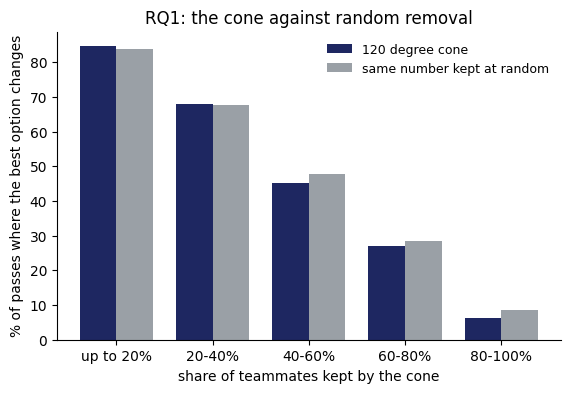

In [5]:
band = pd.cut(k[use] / n[use], [0, 0.2, 0.4, 0.6, 0.8, 1.0],
              labels=['up to 20%', '20-40%', '40-60%', '60-80%', '80-100%'])
by_band = d.assign(band=band).groupby('band', observed=True).agg(
    passes=('real', 'size'), real_cone=('real', 'mean'), random=('rand', 'mean'))
print((by_band.assign(real_cone=100 * by_band['real_cone'], random=100 * by_band['random'])).round(1).to_string())

fig, ax = plt.subplots(figsize=(6.5, 4))
x = np.arange(len(by_band)); w = 0.38
ax.bar(x - w / 2, 100 * by_band['real_cone'], w, color=NAVY, label='120 degree cone')
ax.bar(x + w / 2, 100 * by_band['random'], w, color=GREY, label='same number kept at random')
ax.set_xticks(x); ax.set_xticklabels(by_band.index)
ax.set_xlabel('share of teammates kept by the cone')
ax.set_ylabel('% of passes where the best option changes')
ax.set_title('RQ1: the cone against random removal')
ax.legend(frameon=False, fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
save_fig(fig, 'rq1_random_removal.png')
plt.show()

## 5. A stricter test: the same cone pointed in a random direction

Random removal (sections 2 and 3) drops teammates scattered anywhere around the passer. The real cone drops a block of neighbouring teammates: everyone outside one 120 degree wedge. A stricter test of direction keeps the cone exactly as it is (120 degrees wide, centred on the passer) and only points it in a random direction.

**How it works.** On every pass, a direction is drawn uniformly at random, every teammate within 60 degrees of it is kept, and the best option is recomputed. This is repeated 50 times. A randomly pointed cone does not always keep the same number of teammates as the real one, so the comparison is made at equal numbers: for every combination of teammates in the frame `n` and teammates kept `k`, the random-direction change rate is computed, and each real pass is compared with the rate for its own `n` and `k`.

**A worked example.** A pass has 8 teammates and the real cone keeps 3. Among all random-direction draws (on any pass) that also had 8 teammates and kept 3, suppose the best option changed 65 percent of the time. That 65 percent is the benchmark for this pass.

In [6]:
P = np.stack(c['passer_location'].to_numpy()).astype(float)
direction_to_mate = np.arctan2(c['cand_y'].to_numpy() - P[:, 1], c['cand_x'].to_numpy() - P[:, 0])

rng_dir = np.random.default_rng(1)
draws = []
for r in range(50):
    theta = rng_dir.uniform(-np.pi, np.pi, len(n))                                   # one random direction per pass
    off = np.abs((direction_to_mate - theta[codes] + np.pi) % (2 * np.pi) - np.pi)    # angle from that direction
    inside = off <= np.radians(60)
    kr = np.bincount(codes, weights=inside, minlength=len(n)).astype(int)
    b = np.full(len(n), -np.inf); np.maximum.at(b, codes[inside], v[inside])
    draws.append(pd.DataFrame({'n': n, 'k': kr, 'change': b < best_all - EPS, 'lost': best_all - b}))
draws = pd.concat(draws)
draws = draws[draws['k'] > 0]
print(f"random-direction cones (any number kept): best option changes in {draws['change'].mean():.1%}, "
      f"keeping {(draws['k'] / draws['n']).mean():.1%} of teammates on average")

# benchmark for every real pass: the random-direction rate for the same n and k
cell = draws.groupby(['n', 'k']).agg(rate=('change', 'mean'), lost=('lost', 'mean'), draws=('change', 'size'))
bench = cell.reindex(pd.MultiIndex.from_arrays([n[use], k[use]]))
print(f"every real (n, k) combination has a benchmark: {bench['rate'].notna().all()}, "
      f"fewest random draws behind one benchmark: {int(bench['draws'].min())}")

d['dir_rate'] = bench['rate'].to_numpy()
d['dir_lost'] = bench['lost'].to_numpy()
per_match = d.groupby('m').agg(real=('real', 'sum'), rate=('dir_rate', 'sum'), lost_real=('lost_real', 'sum'),
                               lost_dir=('dir_lost', 'sum'), passes=('real', 'size')).to_numpy()
boot = per_match[rng.integers(0, len(per_match), size=(5000, len(per_match)))].sum(axis=1)
tot = per_match.sum(axis=0)
print(f"\nbest option changes: real cone {tot[0] / tot[4]:.1%}, random direction with the same number kept {tot[1] / tot[4]:.1%}")
print(f"difference {100 * (tot[0] - tot[1]) / tot[4]:+.1f} points "
      f"(95% CI {100 * np.percentile((boot[:, 0] - boot[:, 1]) / boot[:, 4], 2.5):+.1f} to "
      f"{100 * np.percentile((boot[:, 0] - boot[:, 1]) / boot[:, 4], 97.5):+.1f})")
print(f"value lost: real cone {tot[2] / tot[4]:.5f}, random direction {tot[3] / tot[4]:.5f} VAEP, difference "
      f"{(tot[2] - tot[3]) / tot[4]:+.5f} (95% CI {np.percentile((boot[:, 2] - boot[:, 3]) / boot[:, 4], 2.5):+.5f} to "
      f"{np.percentile((boot[:, 2] - boot[:, 3]) / boot[:, 4], 97.5):+.5f})")

by_band2 = d.assign(band=band).groupby('band', observed=True).agg(
    passes=('real', 'size'), real_cone=('real', 'mean'), random_teammates=('rand', 'mean'), random_direction=('dir_rate', 'mean'))
print()
print((by_band2.set_index(by_band2.index.astype(str)).assign(**{col: 100 * by_band2[col].to_numpy() for col in ['real_cone', 'random_teammates', 'random_direction']})).round(1).to_string())

random-direction cones (any number kept): best option changes in 56.8%, keeping 42.6% of teammates on average
every real (n, k) combination has a benchmark: True, fewest random draws behind one benchmark: 659

best option changes: real cone 57.9%, random direction with the same number kept 59.4%
difference -1.5 points (95% CI -1.8 to -1.1)
value lost: real cone 0.00323, random direction 0.00340 VAEP, difference -0.00017 (95% CI -0.00029 to -0.00004)

           passes  real_cone  random_teammates  random_direction
band                                                            
up to 20%   19689       84.6              83.7              84.8
20-40%      27485       68.1              67.8              69.9
40-60%      19579       45.2              47.7              48.2
60-80%      11164       27.0              28.4              27.7
80-100%      4128        6.3               8.5               6.3


## Summary

Two random baselines, both keeping the same number of teammates as the real cone on every pass:

| Benchmark | Best option changes | Value lost (VAEP) |
|---|---|---|
| Real 120 degree cone | 57.9% | 0.0032 |
| Teammates kept at random (scattered) | 58.5% | 0.0028 |
| The same cone pointed in a random direction | 59.4% | 0.0034 |

**The 57.9 percent is explained by how many teammates the cone removes.** On these passes the cone keeps on average 40 percent of the teammates in the frame. Removing the same number at random, scattered or as a randomly pointed wedge, changes the best option at least as often as the real cone.

**The direction of the cone does carry some information, but it works against H1.** Compared with the same cone pointed in a random direction, the real cone changes the best option *less* often (-1.5 points, 95 percent CI -1.8 to -1.1) and loses slightly *less* value (-0.0002 VAEP, CI -0.0003 to -0.00004). The best option is therefore slightly more likely to lie in the direction the passer is moving than in a random direction, not less. Removing a block of neighbouring teammates loses more value than removing scattered ones (0.0034 against 0.0028), because good options tend to sit together, which is why the real cone loses more value than scattered removal but less than a randomly pointed cone.

**What this means for RQ1.** An omniscient model and a model restricted to the 120 degree cone disagree on the best option in about six passes in ten, mainly because the cone keeps fewer than half of the teammates. This is not evidence that many high-value options lie outside the passer's direction of movement. Evidence that the direction relates to passing comes from where passes go: receivers are inside the cone far more often than a random teammate (52.3 against 34.5 percent with the StatsBomb cone, 59.2 against 33.2 percent with the PFF cone; `06_layer3_blind_passes.ipynb` and `11_layer3_pff_rq3_memory.ipynb`).

Saved: `figures/rq1_random_removal.png`.